# Aula 01 - Introdução às Redes Neurais Artificiai

# Setup

In [8]:
# Importar bibliotecas utilizadas no notebook

import numpy as np                  # Computação numérica
import pandas as pd                 # Manipulação de dados
import matplotlib.pyplot as plt     # Geração de gráficos
import ipywidgets as widgets        # Componentes gráficos interativos
from ipywidgets import interactive, fixed  # Interface interativa

# Exibir gráficos no notebook
%matplotlib inline

# Regressão

Objetivo: Compreender como um neurônio aprende ajustando seus parâmetros (**peso** e **bias**) para minimizar o erro entre os valores previstos e os valores observados. Embora o exemplo utilize um problema de regressão linear (y = wx + b), o foco desta etapa é construir a intuição sobre o processo de aprendizado do neurônio.

**Perguntas para discussão**

O que acontece quando alteramos o peso (w)?   
O que acontece quando alteramos o bias (b)?  
Como saber se uma reta é melhor que outra?  
Qual é o papel da função de perda (Loss)?   
Como o algoritmo encontra automaticamente os melhores valores de w e b?  

In [9]:
# Carregar conjunto de dados

df = pd.read_csv("medidas.csv")
print(df.shape)
df.head(10)

(100, 2)


,Altura,Peso
0,187,109.72
1,177,91.09
2,180,88.93
3,177,89.39
4,177,92.02
5,183,94.70
6,178,83.57
7,177,85.19
8,183,92.96
9,188,108.21


Text(0, 0.5, 'Peso')

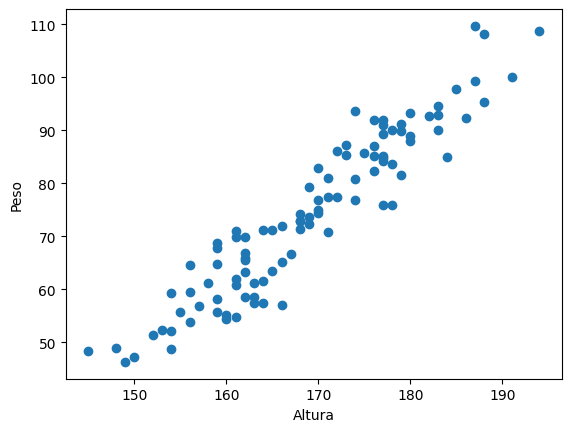

In [10]:
# Visualizar conjunto de dados

x = df.Altura
y = df.Peso

plt.figure()
plt.scatter(x, y)
plt.xlabel('Altura')
plt.ylabel('Peso')

In [11]:
# Definir função para visualização do treinamento

def plot_line(w, b):
    plt.figure(0, figsize=(20, 4))

    # Ajuste da reta aos dados
    plt.subplot(1, 3, 3)
    plt.scatter(x, y)
    y_pred = x * w + b
    plt.plot(x, y_pred, c='red')
    plt.xlim(140, 210)
    plt.ylim(40, 120)

    # Visualização ampliada da reta
    plt.subplot(1, 3, 2)
    x_ = np.array([0, x.max()])
    y_ = x_ * w + b
    plt.scatter(x, y)
    plt.plot(x_, y_, c='red')
    plt.xlim(0, 210)
    plt.ylim(-160, 120)

    # Evolução da função de perda
    plt.subplot(1, 3, 1)
    mse = np.mean((y - y_pred) ** 2)
    loss.append(mse)
    plt.plot(loss)
    plt.title('Loss')

    plt.show()

In [12]:
# Criar interface interativa para ajuste dos parâmetros

loss = []

interactive_plot = interactive(
    plot_line,
    w=(1, 1.5, 0.01),
    b=(-200, 0, 1)
)

output = interactive_plot.children[-1]
output.layout_height = '350px'

interactive_plot

interactive(children=(FloatSlider(value=1.25, description='w', max=1.5, min=1.0, step=0.01), IntSlider(value=-…

In [13]:
# Treinar modelo de regressão linear (y = wx + b)

from sklearn.linear_model import LinearRegression

reg = LinearRegression()
reg.fit(x.values.reshape(-1, 1), y)

print("Equação da reta:")
print("y = {:.2f}x + ({:.2f})".format(reg.coef_[0], reg.intercept_))

print("\nParâmetros:")
print("w: {:.2f}".format(reg.coef_[0]))
print("b: {:.2f}".format(reg.intercept_))

Equação da reta:
y = 1.37x + (-157.47)

Parâmetros:
w: 1.37
b: -157.47


# Classificação

Objetivo: Aplicar o mesmo princípio de aprendizado em um problema de classificação. Agora, os pesos e o bias deixam de ajustar uma reta de regressão e passam a definir uma fronteira de decisão, responsável por separar exemplos pertencentes a diferentes classes.

**Perguntas para discussão**

O que mudou em relação ao exemplo de regressão?  
Qual é o efeito dos pesos (w₁ e w₂) e do bias sobre a fronteira de decisão?  
Por que agora existem dois pesos, enquanto na regressão existia apenas um?  
É possível separar corretamente as duas classes utilizando apenas uma reta?  
O que diferencia os problemas AND, OR e XOR?  


In [14]:
# Definir função para visualização da classificação

def plot_line(w1, w2, b):

    x1, x2 = np.meshgrid(np.linspace(0,1,200), np.linspace(0,1,200))
    x_mesh = np.c_[x1.ravel(), x2.ravel()]

    z_mesh = np.dot(x_mesh, [w1, w2]) + b
    y_mesh = np.where(z_mesh <= 0, 0, 1)

    y_pred = np.dot(x, [w1, w2]) + b
    y_bin = np.where(y_pred <= 0, 0, 1)

    plt.figure(figsize=(10,4))

    plt.subplot(1,2,1)
    loss.append(np.mean((y.ravel()-y_bin)**2))
    plt.plot(loss)
    plt.title('Loss')

    plt.subplot(1,2,2)
    plt.contourf(x1, x2, y_mesh.reshape(x1.shape), cmap='bwr', alpha=0.6)
    plt.contour(x1, x2, z_mesh.reshape(x1.shape), levels=[0], colors='k', linewidths=2)
    plt.scatter(x[:,0], x[:,1], c=y.ravel(), s=100, cmap='bwr', edgecolors='k')

    plt.xlim(0,1)
    plt.ylim(0,1)

    print(f'{y_pred} => {y_bin}')

    plt.show()

### Porta AND

In [15]:
# Definir conjunto de dados para a porta lógica AND

x = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0,0,0,1]]).T

display(pd.DataFrame({
    'x1': x[:,0],
    'x2': x[:,1],
    'Classe': y.ravel()
}))

,x1,x2,Classe
0,0,0,0
1,0,1,0
2,1,0,0
3,1,1,1


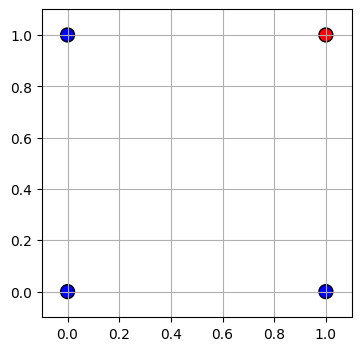

In [16]:
# Visualizar distribuição das classes

plt.figure(figsize=(4,4))
plt.scatter(x[:,0], x[:,1], c=y.ravel(), s=100, cmap='bwr', edgecolors='k')
plt.xlim(-0.1,1.1)
plt.ylim(-0.1,1.1)
plt.grid(True)
plt.show()

In [17]:
# Criar interface interativa para ajuste da fronteira de decisão

loss = []

interactive_plot = interactive(plot_line,
                               w1=(-1,1,0.01),
                               w2=(-1,1,0.01),
                               b=(-1.5,1.5,0.01))

interactive_plot

interactive(children=(FloatSlider(value=0.0, description='w1', max=1.0, min=-1.0, step=0.01), FloatSlider(valu…

### Porta OR

In [18]:
# Definir conjunto de dados para a porta lógica OR

x = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0,1,1,1]]).T

display(pd.DataFrame({
    'x1': x[:,0],
    'x2': x[:,1],
    'Classe': y.ravel()
}))

,x1,x2,Classe
0,0,0,0
1,0,1,1
2,1,0,1
3,1,1,1


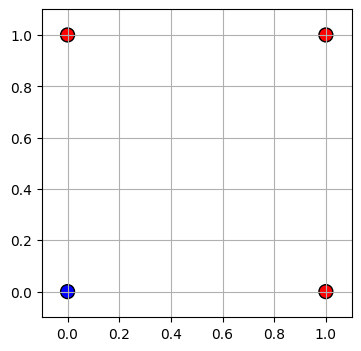

In [19]:
# Visualizar distribuição das classes

plt.figure(figsize=(4,4))
plt.scatter(x[:,0], x[:,1], c=y.ravel(), s=100, cmap='bwr', edgecolors='k')
plt.xlim(-0.1,1.1)
plt.ylim(-0.1,1.1)
plt.grid(True)
plt.show()

In [20]:
# Criar interface interativa para ajuste da fronteira de decisão

loss = []

interactive_plot = interactive(
    plot_line,
    w1=(-1,1,0.01),
    w2=(-1,1,0.01),
    b=(-1.5,1.5,0.01)
)

interactive_plot

interactive(children=(FloatSlider(value=0.0, description='w1', max=1.0, min=-1.0, step=0.01), FloatSlider(valu…

### Porta XOR

In [21]:
# Definir conjunto de dados para a porta lógica XOR

x = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0,1,1,0]]).T

display(pd.DataFrame({
    'x1': x[:,0],
    'x2': x[:,1],
    'Classe': y.ravel()
}))

,x1,x2,Classe
0,0,0,0
1,0,1,1
2,1,0,1
3,1,1,0


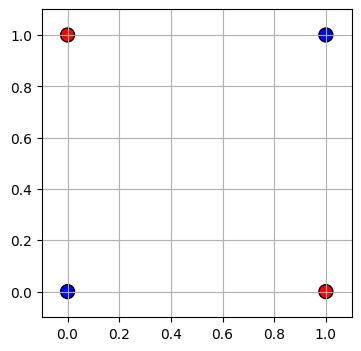

In [22]:
# Visualizar distribuição das classes

plt.figure(figsize=(4,4))
plt.scatter(x[:,0], x[:,1], c=y.ravel(), s=100, cmap='bwr', edgecolors='k')
plt.xlim(-0.1,1.1)
plt.ylim(-0.1,1.1)
plt.grid(True)
plt.show()

In [23]:
# Criar interface interativa para ajuste da fronteira de decisão

loss = []

interactive_plot = interactive(
    plot_line,
    w1=(-1,1,0.01),
    w2=(-1,1,0.01),
    b=(-1.5,1.5,0.01)
)

interactive_plot

interactive(children=(FloatSlider(value=0.0, description='w1', max=1.0, min=-1.0, step=0.01), FloatSlider(valu…